(course-biophysics-comparison-superposition)=

# Path D - Module 34: Comparison & Superposition

Align the channel tetramer to a reference to see how much it deviates from the crystal structure. In this module, you will learn to perform high-symmetry superpositions.

When you use {func}`molsysmt.structure.least_rmsd_fit`, choose at least three non-collinear atom centers in both the input and the reference. Repeated centers do not supply independent anchors. An underdetermined fit raises `StructuralInconsistencyError` before an in-place transformation; translating the same duplicate centers does not make the fit valid. The check uses numerical rank after unit alignment rather than a physical near-collinearity threshold. See {ref}`Least RMSD fit <Tutorial_Least_rmsd_fit>`.


`least_rmsd_align()` returns an aligned molecular system. Use `get_rmsd()`
with the corresponding anchor selections to measure its residual RMSD. Its
selections always address atoms; the sequence provider independently maps their
amino-acid groups. Complete components containing the query anchors move.
See {ref}`Tutorial_Least_rmsd_align` and
{ref}`Cookbook_Aligning_Components_By_Sequence` for ownership and scope details.


(course-biophysics-comparison-superposition-inputs)=
## 1. Preparing a comparison

You compare KcsA potassium channel using the same C-alpha anchor populations
before and after fitting. The aligned system is an independent result: neither
the original query nor the reference is overwritten. Atoms outside the anchors
move when they belong to a selected component; unselected components stay fixed.

Qualify C-alpha anchors by protein membership: another peptide or an ion
can also contain an atom named CA. That extra population must not silently
enter a comparison intended for the target protein.


In [1]:
import molsysmt as msm

reference = msm.convert('pdb:1K4C', to_form='molsysmt.MolSys', structure_indices=[0])

import numpy as np
import matplotlib.pyplot as plt
puw = msm.pyunitwizard
# Create a known displaced protein pose without changing its internal geometry.
molsys = msm.structure.translate(reference,
    selection='molecule_type=="protein"', translation='[0, 1, 0] nm')
atoms = msm.select(molsys, selection='atom_name=="CA" and molecule_type=="protein"')
reference_atoms = msm.select(reference, selection='atom_name=="CA" and molecule_type=="protein"')
reference_before = puw.get_value(msm.get(reference, element='atom', coordinates=True),
                                 to_unit='nm').copy()
query_before = puw.get_value(msm.get(molsys, element='atom', coordinates=True),
                             to_unit='nm').copy()


(course-biophysics-comparison-superposition-raw)=
## 2. Measuring the original difference

Measure raw RMSD over the atoms you will use as fit anchors.


In [2]:
rmsd_raw = msm.structure.get_rmsd(
    molsys, selection=atoms, reference_molecular_system=reference,
    reference_selection=reference_atoms)
print('CA RMSD before alignment:', rmsd_raw)


CA RMSD before alignment: [1.0] nanometer


(course-biophysics-comparison-superposition-fit)=
## 3. Aligning and measuring

Keep the returned system, then measure its RMSD against the same reference.


In [3]:
aligned_molsys = msm.structure.least_rmsd_align(
    molsys, selection=atoms, reference_molecular_system=reference,
    reference_selection=reference_atoms, use_gpu=False)
rmsd_opt = msm.structure.get_rmsd(
    aligned_molsys, selection=atoms, reference_molecular_system=reference,
    reference_selection=reference_atoms)
assert np.all(puw.get_value(rmsd_opt, to_unit='nm') <=
              puw.get_value(rmsd_raw, to_unit='nm') + 1e-10)
np.testing.assert_array_equal(
    puw.get_value(msm.get(reference, element='atom', coordinates=True), to_unit='nm'),
    reference_before)
np.testing.assert_array_equal(
    puw.get_value(msm.get(molsys, element='atom', coordinates=True), to_unit='nm'),
    query_before)
print('CA RMSD after alignment:', rmsd_opt)
assert np.allclose(puw.get_value(rmsd_opt, to_unit='nm'), 0., atol=1e-10)


CA RMSD after alignment: [5.3322191424547165e-15] nanometer


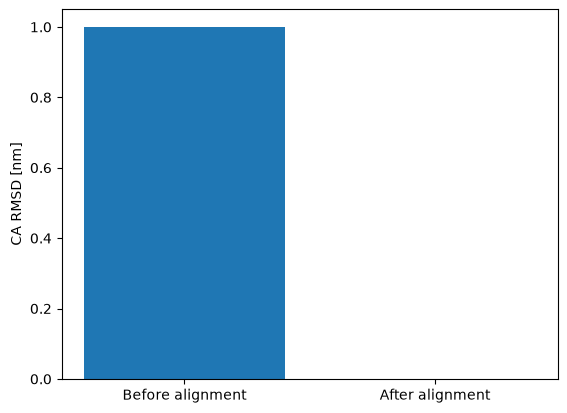

In [4]:
plt.bar(['Before alignment', 'After alignment'],
    [puw.get_value(rmsd_raw, to_unit='nm')[0], puw.get_value(rmsd_opt, to_unit='nm')[0]])
plt.ylabel('CA RMSD [nm]')
plt.show()


(course-biophysics-comparison-superposition-see-also)=
:::{seealso}
:class: dropdown

- {ref}`Tutorial_Least_rmsd_align`
- {ref}`Cookbook_Aligning_Components_By_Sequence`
- {ref}`course-core-structural-operations`
- {func}`molsysmt.structure.get_rmsd`
:::
